# 01 - ETL, validação e engenharia de atributos

**Trabalho N3 - Análise Preditiva (MLOps)** | Etapas 1 e 2 do enunciado | Fluxo: passos 2 e 3

Este notebook abre o ciclo: cria o `cycle_id`, incorpora os dados novos (sem duplicar), diagnostica a
qualidade antes e depois, constrói atributos, define a `data_version`, separa treino/teste e roda o
**monitoramento de drift** (recurso adicional, critério 10).

**Problema (Etapa 1):** prever `churn` (cliente cancela o serviço: 1/0) de um provedor de internet fictício.
Classificação binária; unidade de observação = 1 cliente. **Dados sintéticos** (`src/simulador.py`), sem dados pessoais.
**Métrica principal:** F1 macro (a classe churn é minoria e queremos desempenho equilibrado nas duas classes),
definida em `config/config.yaml` antes de qualquer treino. **Protocolo:** teste fixo por hash do id (20%),
validação cruzada estratificada só no treino. Novos registros chegam em lotes (`data/raw/lote_NNN.csv`).

In [1]:
# Preparação: localiza a raiz do projeto (o nbconvert executa com a pasta notebooks/ como diretório atual)
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow

from src.config import carregar_config, p, dir_, ler_json, gravar_json
from src import ciclo, rastreio

cfg = carregar_config()
pd.set_option("display.width", 160, "display.max_columns", 30)

In [2]:
from src import ingestao, preprocessamento as pre, features as ft, drift

# 1) Novo ciclo: gera cycle_id e incorpora dados novos (arquivo em data/incoming ou lote simulado)
ctx = ciclo.iniciar_ciclo(cfg)
info_ingestao = ingestao.ingerir_novos_dados(cfg, ctx["ha_ciclo_anterior"])
ctx["ingestao"] = info_ingestao
print("cycle_id :", ctx["cycle_id"])
print("gatilho  :", ctx["gatilho"], "| run do Actions:", ctx["github_run_id"] or "-")
print("ingestão :", info_ingestao)

cycle_id : C005_20261126T165209Z
gatilho  : schedule | run do Actions: 45862565222
ingestão : {'origem': 'simulado', 'arquivo': 'lote_004.csv', 'linhas_recebidas': 824, 'indice_lote': 4}


## Diagnóstico ANTES da limpeza
Carregamos todos os lotes de `data/raw` (dados iniciais + lotes novos) e medimos ausentes, duplicações,
valores fora da faixa de domínio e outliers (IQR com fator 3).

In [3]:
bruto = ingestao.carregar_bruto(cfg)
print("Linhas por lote:")
print(bruto.groupby("lote").size().rename("linhas").to_frame().T)
diag_antes = pre.diagnosticar(bruto, cfg)
print(json.dumps(diag_antes, indent=2, ensure_ascii=False))

Linhas por lote:
lote       0    1    2    3    4
linhas  3045  824  824  824  824
{
  "linhas": 6341,
  "duplicadas_exatas": 141,
  "ids_repetidos": 141,
  "ausentes_por_coluna": {
    "forma_pagamento": 97,
    "uso_dados_gb": 129,
    "satisfacao": 188
  },
  "valores_fora_da_faixa": {
    "idade": 34,
    "tempo_contrato_meses": 25,
    "mensalidade": 17,
    "uso_dados_gb": 24
  },
  "outliers_iqr3": {
    "idade": 22,
    "num_servicos": 23,
    "uso_dados_gb": 73,
    "atraso_pagamentos_6m": 1
  },
  "taxa_alvo": 0.23844819429112127
}


## Limpeza (tratamentos justificados)
* **Duplicatas exatas e ids repetidos** (inclusive registros reenviados em lotes posteriores): fica a primeira ocorrência,
  assim um registro novo nunca entra duas vezes.
* **Valores impossíveis/outliers extremos** (idade negativa, mensalidade <= 0, 5.000 GB/mês): são erros de captura. Viram
  *ausente* por **regras fixas de domínio** (`config.yaml`), não por estatística dos dados, o que evita vazamento.
* **Imputação, escala e one-hot**: aprendidos **somente com o treino**, dentro do `ColumnTransformer`.

In [4]:
limpo, resumo_limpeza = pre.limpar_dados(bruto, cfg)
diag_depois = pre.diagnosticar(limpo, cfg)

soma = lambda d: int(sum(d.values()))
comparacao = pd.DataFrame({
    "antes":  {"linhas": diag_antes["linhas"], "duplicadas_exatas": diag_antes["duplicadas_exatas"],
               "ids_repetidos": diag_antes["ids_repetidos"], "ausentes_total": soma(diag_antes["ausentes_por_coluna"]),
               "fora_da_faixa_total": soma(diag_antes["valores_fora_da_faixa"]),
               "outliers_iqr3_total": soma(diag_antes["outliers_iqr3"])},
    "depois": {"linhas": diag_depois["linhas"], "duplicadas_exatas": diag_depois["duplicadas_exatas"],
               "ids_repetidos": diag_depois["ids_repetidos"], "ausentes_total": soma(diag_depois["ausentes_por_coluna"]),
               "fora_da_faixa_total": soma(diag_depois["valores_fora_da_faixa"]),
               "outliers_iqr3_total": soma(diag_depois["outliers_iqr3"])}})
print(resumo_limpeza)
comparacao

{'linhas_entrada': 6341, 'removidas_duplicadas_exatas': 141, 'removidas_id_repetido': 0, 'removidas_sem_alvo': 0, 'linhas_saida': 6200}


,antes,depois
linhas,6341,6200
duplicadas_exatas,141,0
ids_repetidos,141,0
ausentes_total,414,502
fora_da_faixa_total,100,0
outliers_iqr3_total,119,73


> Os *ausentes* sobem depois da limpeza porque os valores impossíveis foram convertidos em ausentes; eles serão
> imputados com a mediana (numéricas) ou a moda (categóricas) **do treino**.

## Engenharia de atributos e versão dos dados
Atributos derivados linha a linha (sem estado): gasto por serviço, chamados por ano de contrato, uso por serviço,
contrato recente e indicador de atraso. A `data_version` é um hash do conjunto limpo: muda sempre que o dado muda.

In [5]:
alvo, idc = cfg["dados"]["alvo"], cfg["dados"]["coluna_id"]
dados = ft.criar_atributos(limpo)

n_lotes = int(bruto["lote"].nunique())
ctx["data_version"] = ingestao.calcular_data_version(limpo.drop(columns=["lote"]), n_lotes, idc)
ctx["n_lotes"], ctx["n_linhas"] = n_lotes, int(len(dados))
print("data_version:", ctx["data_version"], "| lotes:", n_lotes, "| linhas limpas:", len(dados))
dados[ft.COLS_NUM_ENG].describe().T

data_version: v005_1b63121e73 | lotes: 5 | linhas limpas: 6200


,count,mean,std,min,25%,50%,75%,max
gasto_por_servico,6183.0,57.658222,37.041554,7.153333,31.8325,47.380000,72.590000,228.050000
chamados_por_ano,6176.0,1.587793,1.865223,0.000000,0.0000,1.170732,2.285714,14.769231
uso_por_servico,6052.0,82.605909,70.945661,4.200000,36.6000,61.116667,104.537500,833.900000
contrato_recente,6176.0,0.086140,0.280593,0.000000,0.0000,0.000000,0.000000,1.000000
tem_atraso,6200.0,0.321129,0.466948,0.000000,0.0000,0.000000,1.000000,1.000000


## Partição treino/teste e pré-processador (sem vazamento)
O teste é definido pelo **hash do id**: o cliente que cai no teste permanece no teste em todos os ciclos,
então modelos antigos nunca viram o teste atual e a comparação com o vigente é justa mesmo com lotes novos.

In [6]:
treino, teste = pre.dividir_treino_teste(dados, cfg)
assert set(treino[idc]).isdisjoint(set(teste[idc])), "vazamento: ids em treino e teste"
print(f"treino={len(treino)} (churn {treino[alvo].mean():.1%}) | teste={len(teste)} (churn {teste[alvo].mean():.1%})")

X_cols = ft.COLS_NUM + ft.COLS_CAT
pp = pre.construir_preprocessador().fit(treino[X_cols], treino[alvo])
Xt = pp.transform(treino[X_cols])
print("matriz transformada do treino:", Xt.shape)

# Prova de que o imputador aprendeu só com o TREINO (a mediana do treino difere da do conjunto todo)
med_imp = pd.Series(pp.named_transformers_["num"].named_steps["imp"].statistics_, index=ft.COLS_NUM)
assert np.allclose(med_imp.values, treino[ft.COLS_NUM].median().values)
print("medianas do imputador == medianas do treino: OK")

treino=4939 (churn 23.3%) | teste=1261 (churn 26.1%)
matriz transformada do treino: (4939, 36)
medianas do imputador == medianas do treino: OK


## Monitoramento de drift (recurso adicional - critério 10)
O lote novo é comparado com o histórico por **PSI** (< 0,10 estável; 0,10-0,25 atenção; >= 0,25 alerta) e **KS**.
O resultado é gravado em `evidencias/<cycle_id>/`, registrado no MLflow e lido pelo workflow, que emite alerta.

{
  "avaliado": true,
  "n_ref": 5400,
  "n_novo": 800,
  "max_psi": 0.41305407266681654,
  "atributo_max_psi": "mensalidade",
  "n_features_alerta": 1,
  "n_features_atencao": 3,
  "taxa_alvo_ref": 0.22037037037037038,
  "taxa_alvo_novo": 0.36125,
  "alerta": true,
  "features_em_alerta": [
    "mensalidade"
  ]
}


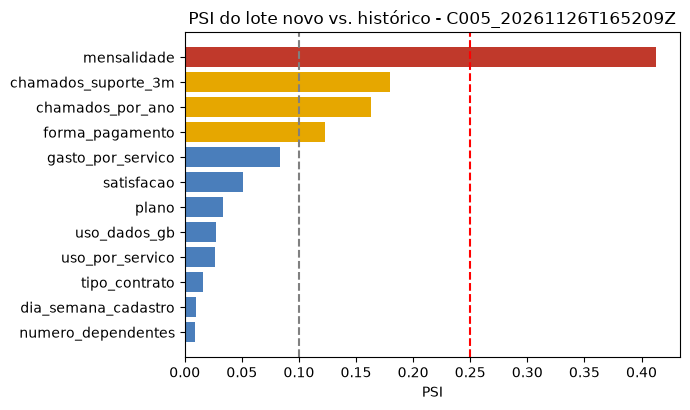

,atributo,tipo,psi,ks_estatistica,ks_p_valor,media_ref,media_novo,status
0,mensalidade,numérico,0.413,0.187,0.000,108.774,126.190,ALERTA
1,chamados_suporte_3m,numérico,0.179,0.172,0.000,0.989,1.526,atenção
2,chamados_por_ano,numérico,0.163,0.166,0.000,1.486,2.278,atenção
3,forma_pagamento,categórico,0.123,NaN,NaN,NaN,NaN,atenção
4,gasto_por_servico,numérico,0.084,0.116,0.000,56.549,65.146,estável
5,satisfacao,numérico,0.051,0.093,0.000,3.607,3.398,estável
6,plano,categórico,0.033,NaN,NaN,NaN,NaN,estável
7,uso_dados_gb,numérico,0.027,0.077,0.001,156.223,171.841,estável
8,uso_por_servico,numérico,0.027,0.051,0.056,81.633,89.174,estável
9,tipo_contrato,categórico,0.016,NaN,NaN,NaN,NaN,estável


In [7]:
ev = ciclo.dir_evidencias(ctx)
ev.mkdir(parents=True, exist_ok=True)

if info_ingestao.get("indice_lote") is None:
    resumo_drift = drift.resumo_sem_referencia(info_ingestao.get("motivo", "sem lote novo neste ciclo"))
    tab_drift = None
else:
    ult = int(dados["lote"].max())
    ref, novo = dados[dados["lote"] < ult], dados[dados["lote"] == ult]
    tab_drift, resumo_drift = drift.relatorio_drift(ref, novo, ft.COLS_NUM, ft.COLS_CAT, alvo, cfg)

print(json.dumps(resumo_drift, indent=2, ensure_ascii=False))
if tab_drift is not None:
    tab_drift.to_csv(ev / "drift_report.csv", index=False)
    top = tab_drift.head(12).iloc[::-1]
    cores = top["status"].map({"ALERTA": "#c0392b", "atenção": "#e6a700", "estável": "#4a7ebb"})
    plt.figure(figsize=(7, 4.2))
    plt.barh(top["atributo"], top["psi"], color=cores)
    plt.axvline(cfg["drift"]["psi_aviso"], ls="--", c="gray")
    plt.axvline(cfg["drift"]["psi_alerta"], ls="--", c="red")
    plt.title(f"PSI do lote novo vs. histórico - {ctx['cycle_id']}")
    plt.xlabel("PSI"); plt.tight_layout()
    plt.savefig(ev / "drift_psi.png", dpi=130); plt.show()
    display(tab_drift.head(10).round(3))

## Persistência dos artefatos do ciclo e registro no MLflow

In [8]:
proc = dir_(cfg, "dir_processed")
dados.to_csv(proc / "dados_limpos.csv", index=False)
treino.to_csv(proc / "treino.csv", index=False)
teste.to_csv(proc / "teste.csv", index=False)

# registros SEM rótulo para o notebook 05 (clientes a pontuar; ids fora de treino/teste)
ctx["scoring_path"] = str(ingestao.gerar_registros_producao(cfg, int(dados["lote"].max())).relative_to(p()))
gravar_json(ev / "diagnostico_etl.json", {"antes": diag_antes, "limpeza": resumo_limpeza, "depois": diag_depois,
                                          "ingestao": info_ingestao})
gravar_json(ev / "drift_resumo.json", resumo_drift)
ctx["drift"] = resumo_drift

rastreio.configurar(cfg)
with rastreio.run("etl_ingestao", ctx, etapa="etl", tags_extra={"drift_alerta": str(resumo_drift["alerta"]).lower()}) as r:
    mlflow.log_params({"n_lotes": n_lotes, "linhas_limpas": len(dados), "linhas_treino": len(treino),
                       "linhas_teste": len(teste), "origem_novo_lote": info_ingestao["origem"],
                       "fracao_teste": cfg["avaliacao"]["fracao_teste"]})
    mlflow.log_metrics({"duplicadas_removidas": resumo_limpeza["removidas_duplicadas_exatas"] + resumo_limpeza["removidas_id_repetido"],
                        "taxa_churn_treino": float(treino[alvo].mean()),
                        "drift_max_psi": resumo_drift["max_psi"], "drift_n_features_alerta": resumo_drift["n_features_alerta"]})
    mlflow.log_artifact(str(ev / "diagnostico_etl.json")); mlflow.log_artifact(str(ev / "drift_resumo.json"))
    for extra in ("drift_report.csv", "drift_psi.png"):
        if (ev / extra).exists():
            mlflow.log_artifact(str(ev / extra))
    ctx["run_ids"]["etl"] = r.info.run_id
ciclo.salvar_contexto(cfg, ctx)
print("OK - contexto do ciclo salvo:", ctx["cycle_id"], ctx["data_version"])

OK - contexto do ciclo salvo: C005_20261126T165209Z v005_1b63121e73
